# Experiment 2: Support Vector Machines
**Machine Learning | Autumn 2026**  
**Release:** October 13, 2026 | **Deadline:** November 11, 2026

Implement linear and nonlinear SVMs, inspect their hyperparameters, evaluate a
real dataset correctly, and implement a linear SVM using NumPy.

Tasks 1-4 are **required**. Task 5 is **optional**.

Use Python and write the report in English. Submit your completed `.ipynb`
(with outputs) and `report.pdf`; use `Template.doc` for the report structure.
Work independently and explain the results, rather than submitting plots alone.

- Tasks 1-3 and 5: scikit-learn is allowed.
- Task 4: implement training, loss, gradients, and prediction with NumPy only.
  Pandas/Matplotlib may be used for loading/plotting, and sklearn only for the reference model.
- Fill the marked blocks and the report questions. `NotImplementedError` identifies
  unfinished code deliberately; it is not an installation problem.
- Start Jupyter from the folder containing this notebook and the two CSV files.
  Select a Python kernel with NumPy, pandas, Matplotlib, SciPy, scikit-learn,
  seaborn and ipykernel installed; restart it before a final Run All.
  No GPU or dataset download is required.

If packages are missing, install them in the Python environment used by your
notebook: `python -m pip install numpy pandas matplotlib scipy scikit-learn
seaborn ipykernel jupyterlab`. Start Jupyter with `python -m jupyterlab`.


**Instructor reference.** This notebook implements every task, including Task 5. Numerical results may vary slightly across library versions. Grade the reasoning and implementation, not exact floating-point values.


In [1]:
import time
import platform
import sys
import importlib.metadata as metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, make_scorer, classification_report,
                             confusion_matrix)

SEED = 42
N_JOBS = 2
GRID_RESOLUTION = 160
DATA_DIR = Path.cwd()
assert all((DATA_DIR / f).is_file() for f in ("T1_data.csv", "T2_data.csv")), (
    "Start Jupyter in the folder containing this notebook and both CSV files.")
task_times = {}
notebook_started = time.perf_counter()
print("Python:", sys.version.split()[0], "| CPU:", platform.processor())
for package in ["numpy", "pandas", "matplotlib", "scipy", "scikit-learn", "seaborn"]:
    print(f"{package}: {metadata.version(package)}")


Python: 3.12.10 | CPU: Intel64 Family 6 Model 197 Stepping 2, GenuineIntel
numpy: 2.5.3
pandas: 3.0.6
matplotlib: 3.11.2
scipy: 1.18.1
scikit-learn: 1.9.1
seaborn: 0.13.2


### Provided plotting helper
The same helper works for sklearn models, Pipelines, and the NumPy model. It receives its data and axes explicitly; it never uses task-global features or labels.


In [2]:
def plot_decision_boundary(model, X, y, ax, title="", support_vectors=None):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    lower, upper = X.min(axis=0), X.max(axis=0)
    padding = np.maximum((upper - lower) * 0.08, 0.1)
    xx, yy = np.meshgrid(
        np.linspace(lower[0] - padding[0], upper[0] + padding[0], GRID_RESOLUTION),
        np.linspace(lower[1] - padding[1], upper[1] + padding[1], GRID_RESOLUTION))
    mesh = np.column_stack([xx.ravel(), yy.ravel()])
    predictions = model.predict(mesh).reshape(xx.shape)
    ax.contourf(xx, yy, predictions, levels=[-2, 0, 2],
                colors=["#f9d5d5", "#c9e2f5"], alpha=0.65)
    scores = model.decision_function(mesh).reshape(xx.shape)
    ax.contour(xx, yy, scores, levels=[-1, 0, 1], colors="black",
               linestyles=["--", "-", "--"], linewidths=0.8)
    for label, color in [(-1, "#ba3434"), (1, "#236a9a")]:
        mask = y == label
        ax.scatter(X[mask, 0], X[mask, 1], c=color, s=22,
                   edgecolors="black", linewidths=0.3, label=str(label))
    if support_vectors is not None:
        support_vectors = np.asarray(support_vectors)
        ax.scatter(support_vectors[:, 0], support_vectors[:, 1],
                   facecolors="none", edgecolors="black", s=80,
                   linewidths=0.8, label="Support vectors")
    ax.set(xlabel="Feature 1", ylabel="Feature 2", title=title)
    ax.legend(fontsize=8)


## Task 1 Required: Linear SVM
For labels $y_i\in\{-1,+1\}$, the soft-margin primal is
$$
\min_{w,b,\xi}\frac12\|w\|^2+C\sum_i\xi_i,
\quad y_i(w^T x_i+b)\geq1-\xi_i,\quad\xi_i\geq0.
$$
Load `T1_data.csv`: 51 rows, two features, and a label column. Visualize the
data, fit a linear SVM, and show the decision boundary and the two margin contours.
Compare $C=0.01,0.1,1,10,100,1000$. These are full-dataset illustrations;
training accuracy is not an estimate of performance on unseen data.


In [3]:
task_started = time.perf_counter()
########## Start of Your Code ##########
t1 = pd.read_csv(DATA_DIR / "T1_data.csv")
X_t1 = t1.iloc[:, :2].to_numpy(dtype=float)
y_t1 = t1["label"].to_numpy(dtype=int)
########## End of Your Code ############
assert X_t1.shape == (51, 2) and y_t1.shape == (51,)
assert set(np.unique(y_t1)) == {-1, 1}
print(X_t1.shape, y_t1.shape)


(51, 2) (51,)


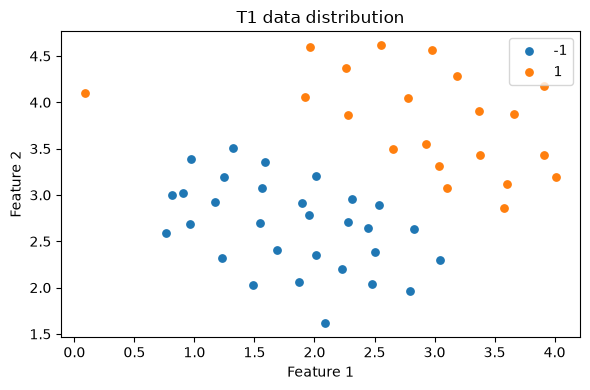

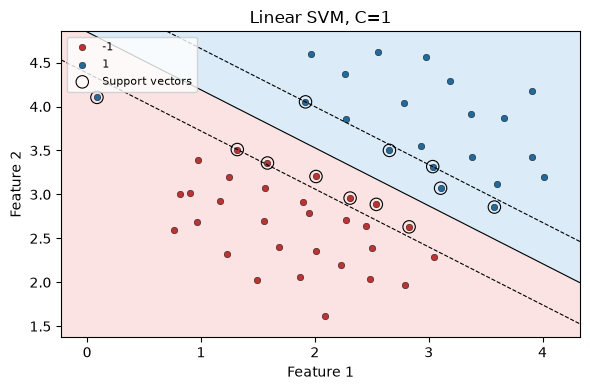

In [4]:
########## Start of Your Code ##########
fig, ax = plt.subplots(figsize=(6, 4))
for label in [-1, 1]:
    ax.scatter(*X_t1[y_t1 == label].T, label=str(label), s=28)
ax.set(xlabel="Feature 1", ylabel="Feature 2", title="T1 data distribution")
ax.legend()
fig.tight_layout()
plt.show()
clf_linear = SVC(kernel="linear", C=1).fit(X_t1, y_t1)
fig, ax = plt.subplots(figsize=(6, 4))
plot_decision_boundary(clf_linear, X_t1, y_t1, ax,
                       "Linear SVM, C=1", clf_linear.support_vectors_)
fig.tight_layout()
plt.show()
########## End of Your Code ############


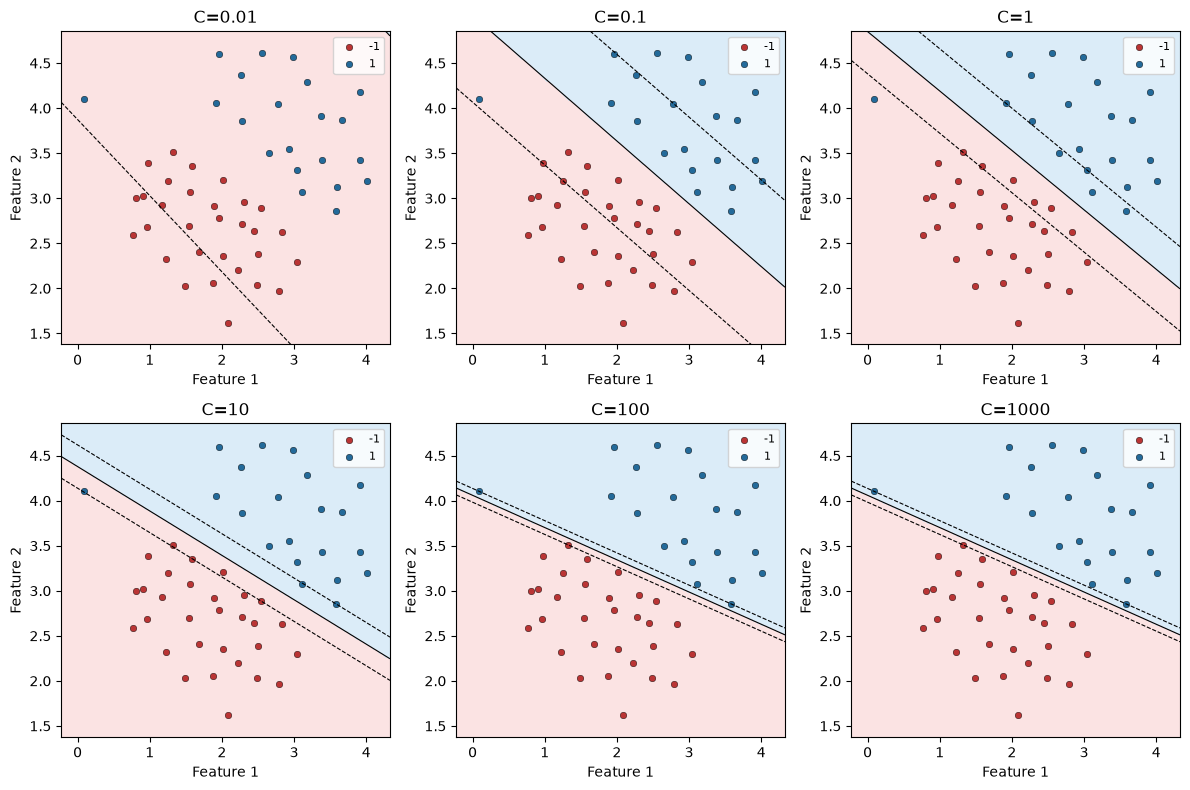

In [5]:
C_t1 = [0.01, 0.1, 1, 10, 100, 1000]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
########## Start of Your Code ##########
for C, ax in zip(C_t1, axes.flat):
    model = SVC(kernel="linear", C=C).fit(X_t1, y_t1)
    plot_decision_boundary(model, X_t1, y_t1, ax, f"C={C}")
########## End of Your Code ############
fig.tight_layout()
plt.show()
task_times["Task 1"] = time.perf_counter() - task_started


**Reference analysis.** Larger C penalizes margin violations more strongly and
can change both the orientation and width of the margin. The geometric width
for a linear model is $2/\|w\|$. A larger C does not guarantee higher unseen-data
accuracy; the plots describe fitted models on the same 51 observations.


## Task 2 Required: Nonlinear SVM
The soft-margin dual can be written as
$$
\min_\alpha\frac12\sum_{i,j}\alpha_i\alpha_jy_iy_jK(x_i,x_j)-\sum_i\alpha_i,
\quad\sum_i\alpha_i y_i=0,\quad0\leq\alpha_i\leq C.
$$
For the RBF kernel,
$$
K(x,z)=\exp(-\gamma\|x-z\|^2),\qquad\gamma=\frac{1}{2\sigma^2}.
$$
Gamma and sigma are different parameterizations: larger gamma means a narrower
kernel. Load the 200 rows of `T2_data.csv`. Fit an RBF SVM and visualize the
nine combinations of $C=[0.1,1,10]$ and $\gamma=[0.1,1,10]$.


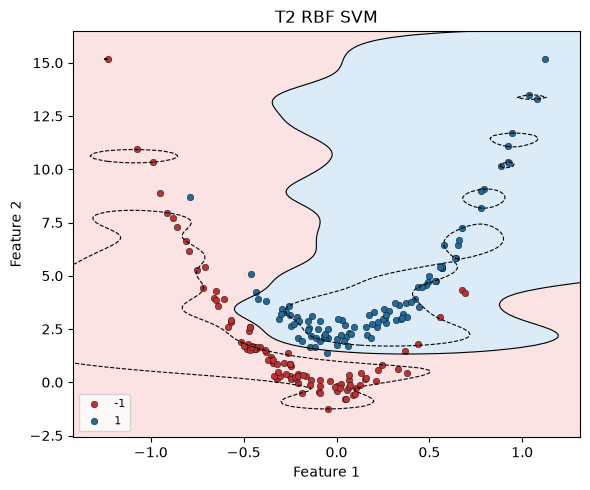

In [6]:
task_started = time.perf_counter()
########## Start of Your Code ##########
t2 = pd.read_csv(DATA_DIR / "T2_data.csv")
X_t2 = t2.iloc[:, :2].to_numpy(dtype=float)
y_t2 = t2["label"].to_numpy(dtype=int)
clf_rbf = SVC(kernel="rbf", C=1, gamma=1).fit(X_t2, y_t2)
fig, ax = plt.subplots(figsize=(6, 5))
plot_decision_boundary(clf_rbf, X_t2, y_t2, ax, "T2 RBF SVM")
fig.tight_layout()
plt.show()
########## End of Your Code ############
assert X_t2.shape == (200, 2) and y_t2.shape == (200,)
assert set(np.unique(y_t2)) == {-1, 1}


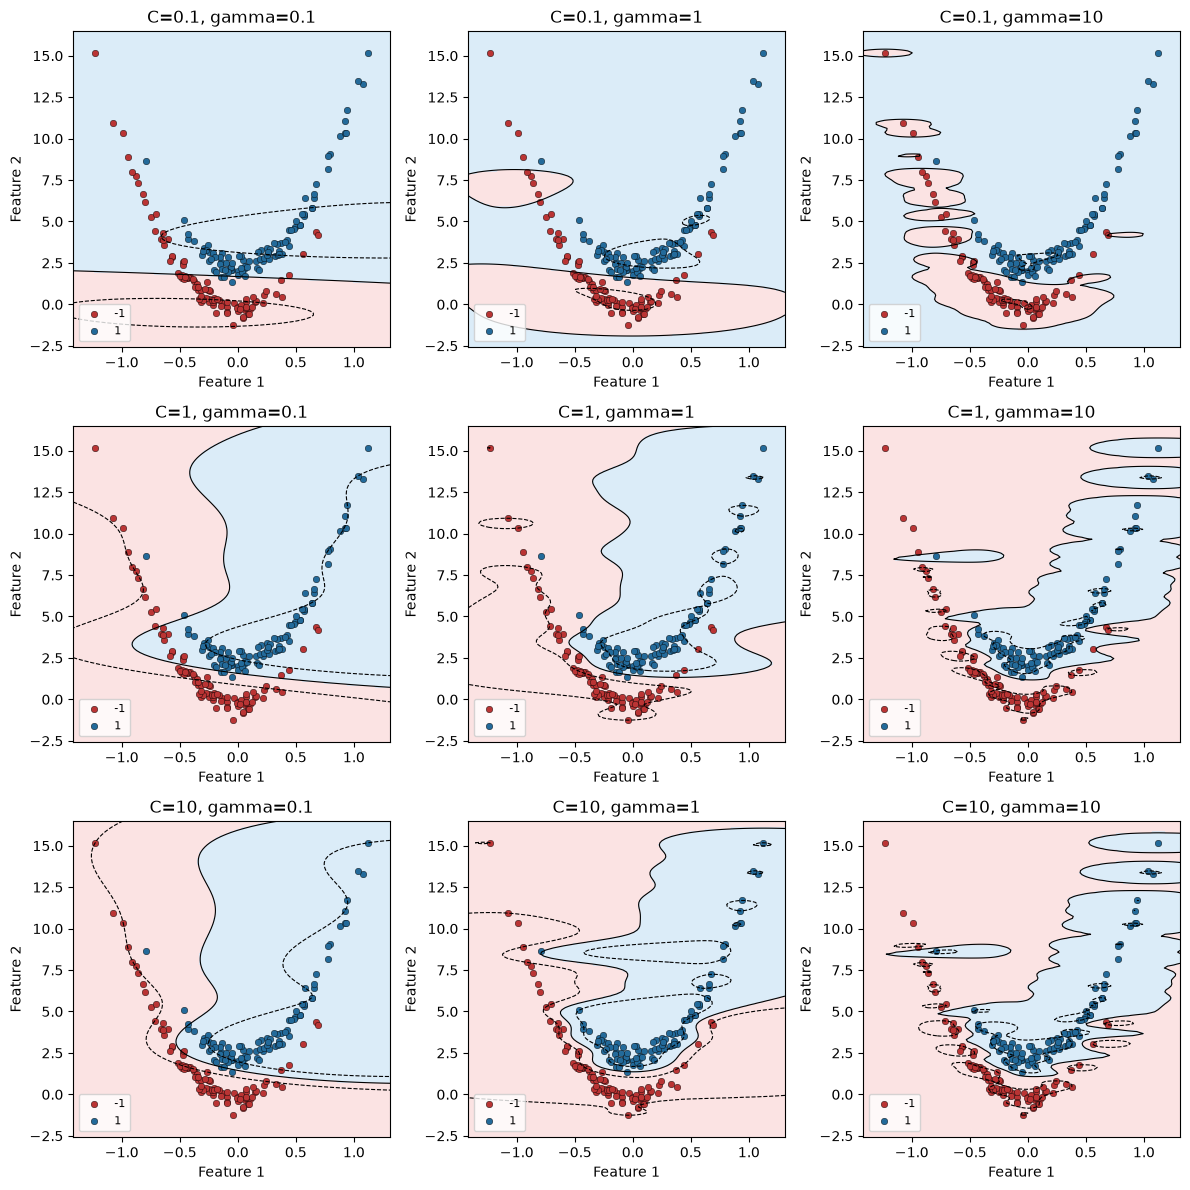

In [7]:
C_visual = [0.1, 1, 10]
gamma_visual = [0.1, 1, 10]
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
########## Start of Your Code ##########
for row, C in enumerate(C_visual):
    for col, gamma in enumerate(gamma_visual):
        model = SVC(kernel="rbf", C=C, gamma=gamma).fit(X_t2, y_t2)
        plot_decision_boundary(model, X_t2, y_t2, axes[row, col],
                               f"C={C}, gamma={gamma}")
########## End of Your Code ############
fig.tight_layout()
plt.show()


### Cross-validation grid search
Use all 21 values $2^{-10},2^{-9},\ldots,2^{10}$ for **each** of C and gamma
(441 combinations, 2205 fold fits). Use five-fold stratified cross-validation
with shuffle enabled and random state 42; score accuracy. Report `best_params_`
and `best_score_` and plot the mean validation accuracy as a 21-by-21 heatmap.
This full-data CV is a tuning demonstration. Its best score is **not** an
independent test score; Task 5 demonstrates a separate held-out test protocol.


In [8]:
########## Start of Your Code ##########
resolution = 21
param_grid = {"C": 2.0 ** np.arange(-10, 11),
              "gamma": 2.0 ** np.arange(-10, 11)}
cv_t2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid_search = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=cv_t2,
                           scoring="accuracy", n_jobs=N_JOBS, error_score="raise")
grid_search.fit(X_t2, y_t2)
########## End of Your Code ############
print("Best parameters:", grid_search.best_params_)
print(f"Best tuning CV accuracy: {grid_search.best_score_:.4f}")


Best parameters: {'C': np.float64(256.0), 'gamma': np.float64(0.25)}
Best tuning CV accuracy: 0.9800


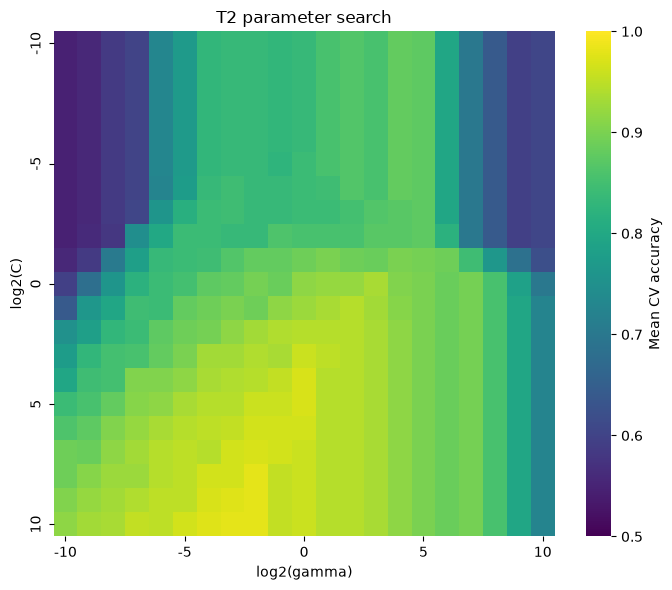

In [9]:
########## Start of Your Code ##########
scores_t2 = grid_search.cv_results_["mean_test_score"].reshape(21, 21)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(scores_t2, ax=ax, cmap="viridis", vmin=0.5, vmax=1,
            cbar_kws={"label": "Mean CV accuracy"})
positions = np.array([0, 5, 10, 15, 20]) + 0.5
ax.set_xticks(positions, labels=[-10, -5, 0, 5, 10])
ax.set_yticks(positions, labels=[-10, -5, 0, 5, 10])
ax.set(xlabel="log2(gamma)", ylabel="log2(C)", title="T2 parameter search")
fig.tight_layout()
plt.show()
########## End of Your Code ############
task_times["Task 2"] = time.perf_counter() - task_started


**Reference analysis.** A large gamma makes similarity highly local and can
create complicated boundaries. C controls the cost of violations; it does not
have the same role as gamma. Heatmap regions, rather than one isolated maximum,
show sensitivity to hyperparameters. The best CV result was selected using
these same folds, so it should not be presented as independent test performance.


## Task 3 Required: SVM on the Wisconsin Breast Cancer Dataset
Load `load_breast_cancer()` (569 samples, 30 features). Retain its original
labels: **0 = malignant**, **1 = benign**. Here malignant is the positive class
for precision, recall and F1, so use `pos_label=0` explicitly.

Split 80%/20% with `stratify=y` and `random_state=42`. Keep the raw features
in `X_train` and `X_test`. All model selection happens within the training set.
Standardization learns means/scales; place it **inside** the cross-validation
Pipeline so each validation fold remains unseen during fitting.


In [10]:
task_started = time.perf_counter()
########## Start of Your Code ##########
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target, name="target")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
########## End of Your Code ############
assert isinstance(X, pd.DataFrame) and isinstance(y, pd.Series)
assert X.shape == (569, 30)
assert X_train.shape == (455, 30) and X_test.shape == (114, 30)
print("Original target names:", dict(enumerate(cancer.target_names)))
print("Training classes:", y_train.value_counts().sort_index().to_dict())
print("Test classes:", y_test.value_counts().sort_index().to_dict())


Original target names: {0: np.str_('malignant'), 1: np.str_('benign')}
Training classes: {0: 170, 1: 285}
Test classes: {0: 42, 1: 72}


### Scaling demonstration
Create `X_train_scaled_demo` using only training data to check the transformation. This demonstration does not replace the raw `X_train` passed to GridSearchCV; the formal search must fit its own scaler inside each fold. Scaling equalizes feature units, but does not guarantee equal predictive importance.


In [11]:
########## Start of Your Code ##########
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)
########## End of Your Code ############
assert np.allclose(X_train_scaled_demo.mean(axis=0), 0, atol=1e-7)
assert np.allclose(X_train_scaled_demo.std(axis=0), 1, atol=1e-7)


### Tune on the raw training features through a Pipeline
Use exactly seven values $10^{-3},\ldots,10^3$ for C and seven values
$10^{-4},\ldots,10^2$ for gamma. Use five-fold stratified CV with shuffle and
seed 42. Score **malignant F1**, using `make_scorer(f1_score, pos_label=0)`.
The Pipeline step names are `scaler` and `svc`, so parameter names are
`svc__C` and `svc__gamma`. Store the fitted search in `grid_search_cancer`.


In [12]:
########## Start of Your Code ##########
cancer_pipeline = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf"))])
param_grid_cancer = {"svc__C": 10.0 ** np.arange(-3, 4),
                     "svc__gamma": 10.0 ** np.arange(-4, 3)}
cv_cancer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
malignant_f1 = make_scorer(f1_score, pos_label=0, zero_division=0)
grid_search_cancer = GridSearchCV(cancer_pipeline, param_grid_cancer,
    scoring=malignant_f1, cv=cv_cancer, n_jobs=N_JOBS, error_score="raise")
grid_search_cancer.fit(X_train, y_train)
########## End of Your Code ############
print("Best parameters:", grid_search_cancer.best_params_)
print(f"Best malignant F1 (tuning CV): {grid_search_cancer.best_score_:.4f}")


Best parameters: {'svc__C': np.float64(10.0), 'svc__gamma': np.float64(0.01)}
Best malignant F1 (tuning CV): 0.9668


### Evaluate the selected model once on the test set
Report accuracy and malignant precision, recall and F1. With original label order `[0, 1]`, malignant false negatives appear in matrix row 0, column 1: true malignant predicted benign. This dataset experiment does not establish clinical suitability.


,Test score
accuracy,0.982456
malignant_precision,0.976190
malignant_recall,0.976190
malignant_f1,0.976190


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



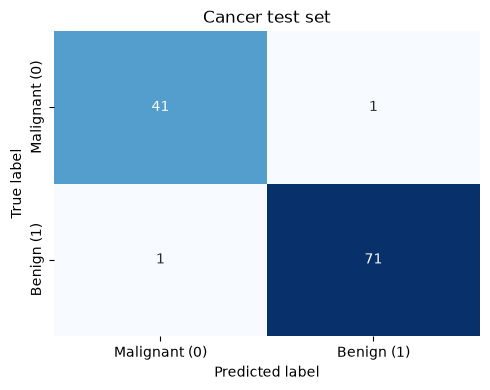

In [13]:
########## Start of Your Code ##########
y_pred = grid_search_cancer.best_estimator_.predict(X_test)
cancer_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "malignant_precision": precision_score(y_test, y_pred, pos_label=0, zero_division=0),
    "malignant_recall": recall_score(y_test, y_pred, pos_label=0, zero_division=0),
    "malignant_f1": f1_score(y_test, y_pred, pos_label=0, zero_division=0)}
display(pd.Series(cancer_metrics, name="Test score").to_frame())
print(classification_report(y_test, y_pred, labels=[0, 1],
      target_names=["malignant", "benign"], zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Malignant (0)", "Benign (1)"],
            yticklabels=["Malignant (0)", "Benign (1)"])
ax.set(xlabel="Predicted label", ylabel="True label", title="Cancer test set")
fig.tight_layout()
plt.show()
########## End of Your Code ############
task_times["Task 3"] = time.perf_counter() - task_started


In [14]:
display(Markdown(
    f"**Reference interpretation.** The selected model misses **{cm[0, 1]}** "
    f"malignant cases and labels **{cm[1, 0]}** benign cases as malignant. "
    f"Malignant recall is **{cancer_metrics['malignant_recall']:.4f}**. "
    "The original default binary F1 would instead describe benign cases. "
    "The test set never fitted the scaler or selected C/gamma. The best CV "
    "score and test score assess different data and need not agree."))


**Reference interpretation.** The selected model misses **1** malignant cases and labels **1** benign cases as malignant. Malignant recall is **0.9762**. The original default binary F1 would instead describe benign cases. The test set never fitted the scaler or selected C/gamma. The best CV score and test score assess different data and need not agree.

## Task 4 Required: Implement a Linear SVM Using NumPy
Implement the hinge-loss objective with a **sum**, not a mean:
$$
L(w,b)=\frac12\|w\|^2+C\sum_i\max(0,1-y_i(w^Tx_i+b)).
$$
The bias is not regularized. Derive subgradients using the active set
$A=\{i:y_i(w^Tx_i+b)<1\}$; at exactly margin 1 choose the inactive branch.
Use the provided full-batch loop: initialize zero parameters, update 5000 times
with $\eta_t=0.05/\sqrt{t+1}$, and retain the lowest-loss parameters, including
the initial state. Raw losses may fluctuate; monotonic decrease is not required.

Complete `loss`, `subgradient`, the update, `decision_function`, and `predict`.
Prediction at score zero must be +1. Only NumPy may implement this model; do not
call sklearn estimators, automatic differentiation, or optimization libraries
inside the class. sklearn is allowed only for the reference comparison below.


In [15]:
task_started = time.perf_counter()
# Provided: Task 4 reloads T1, without depending on overwritten task variables.
t4_data = pd.read_csv(DATA_DIR / "T1_data.csv")
X_t4_raw = t4_data.iloc[:, :2].to_numpy(dtype=float)
y_t4 = t4_data["label"].to_numpy(dtype=int)
t4_mean = X_t4_raw.mean(axis=0)
t4_scale = X_t4_raw.std(axis=0)
t4_scale = np.where(t4_scale == 0, 1, t4_scale)
X_t4 = (X_t4_raw - t4_mean) / t4_scale


In [16]:
class NumPyLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.05, n_iter=5000):
        if C <= 0 or learning_rate <= 0 or n_iter <= 0:
            raise ValueError("C, learning_rate, and n_iter must be positive")
        self.C = C
        self.learning_rate = learning_rate
        self.n_iter = n_iter

    def loss(self, X, y, w, b):
        ########## Start of Your Code ##########
        margins = y * (X @ w + b)
        return float(0.5 * (w @ w) + self.C * np.maximum(0, 1 - margins).sum())
        ########## End of Your Code ############

    def subgradient(self, X, y, w, b):
        ########## Start of Your Code ##########
        active = y * (X @ w + b) < 1
        grad_w = w - self.C * (X[active].T @ y[active])
        grad_b = -self.C * y[active].sum()
        return grad_w, float(grad_b)
        ########## End of Your Code ############

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        if X.ndim != 2 or y.shape != (len(X),) or not np.isin(y, [-1, 1]).all():
            raise ValueError("Expected a feature matrix and one-dimensional -1/+1 labels")
        w, b = np.zeros(X.shape[1]), 0.0
        best_w, best_b = w.copy(), b
        self.best_loss_ = self.loss(X, y, w, b)
        self.loss_history_ = [self.best_loss_]
        for t in range(self.n_iter):
            grad_w, grad_b = self.subgradient(X, y, w, b)
            eta = self.learning_rate / np.sqrt(t + 1)
            ########## Start of Your Code ##########
            w = w - eta * grad_w
            b = b - eta * grad_b
            ########## End of Your Code ############
            current_loss = self.loss(X, y, w, b)
            if not np.isfinite(current_loss):
                raise FloatingPointError("Non-finite loss; check gradients and update")
            self.loss_history_.append(current_loss)
            if current_loss < self.best_loss_:
                self.best_loss_ = current_loss
                best_w, best_b = w.copy(), b
        self.w_, self.b_ = best_w, best_b
        self.loss_history_ = np.asarray(self.loss_history_)
        return self

    def decision_function(self, X):
        ########## Start of Your Code ##########
        return np.asarray(X, dtype=float) @ self.w_ + self.b_
        ########## End of Your Code ############

    def predict(self, X):
        ########## Start of Your Code ##########
        return np.where(self.decision_function(X) >= 0, 1, -1)
        ########## End of Your Code ############


### Provided numerical gradient check
This checks a point away from hinge-loss kinks using central differences. It also checks prediction at zero. Passing this check is necessary, but does not alone prove that training is correct.


In [17]:
check_model = NumPyLinearSVM(C=0.7)
check_X = np.array([[0.2, -0.3], [0.7, 0.4], [-0.5, 0.1]])
check_y = np.array([1, -1, 1])
eps = 1e-6
gradient_errors = []
# All-active, mixed-active, and no-active samples exercise all branches.
for theta in [np.array([0.1, -0.2, 0.05]), np.array([3.0, -2.0, 0.5]),
              np.array([-3.0, -4.0, 1.5])]:
    assert np.min(np.abs(check_y * (check_X @ theta[:2] + theta[2]) - 1)) > 0.1
    analytic_w, analytic_b = check_model.subgradient(check_X, check_y, theta[:2], theta[2])
    analytic = np.r_[analytic_w, analytic_b]
    numeric = np.empty(3)
    for j in range(3):
        delta = np.zeros(3)
        delta[j] = eps
        plus, minus = theta + delta, theta - delta
        numeric[j] = (check_model.loss(check_X, check_y, plus[:2], plus[2]) -
                      check_model.loss(check_X, check_y, minus[:2], minus[2])) / (2 * eps)
    assert np.allclose(analytic, numeric, atol=1e-6, rtol=1e-5)
    gradient_errors.append(float(np.max(np.abs(analytic - numeric))))
check_model.w_, check_model.b_ = np.zeros(2), 0.0
assert check_model.predict(np.zeros((1, 2)))[0] == 1
print("Maximum subgradient error:", max(gradient_errors))
print("Zero-score prediction: +1; gradient check passed.")


Maximum subgradient error: 6.433289456708735e-10
Zero-score prediction: +1; gradient check passed.


### Compare C = 0.1, 1, 10 against sklearn
Train both implementations on the same NumPy-standardized T1 data and use the
same C. For each model report training accuracy, objective value and geometric
margin width $2/\|w\|$ **in standardized coordinates**. Plot the NumPy loss
histories and six boundaries. The comparison is about optimization, not test
generalization. A finite-step solver need not reproduce sklearn's coefficients.


,C,implementation,train_accuracy,objective,margin_width,relative_objective_gap
0,0.1,NumPy,0.980392,1.621345,1.853665,0.000000
1,0.1,sklearn,0.980392,1.621345,1.853723,0.000000
2,1.0,NumPy,0.980392,6.386453,0.878077,0.000003
3,1.0,sklearn,0.980392,6.386436,0.878091,0.000000
4,10.0,NumPy,0.980392,29.202941,0.428691,0.000638
5,10.0,sklearn,0.980392,29.184327,0.435431,0.000000


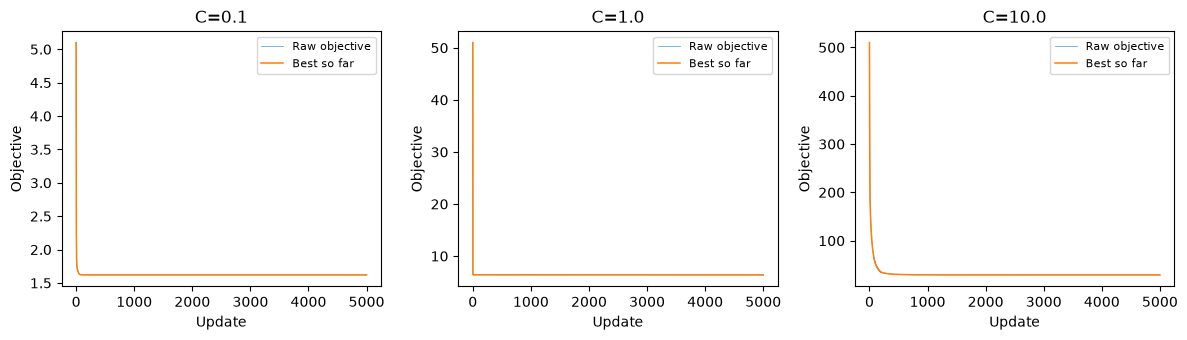

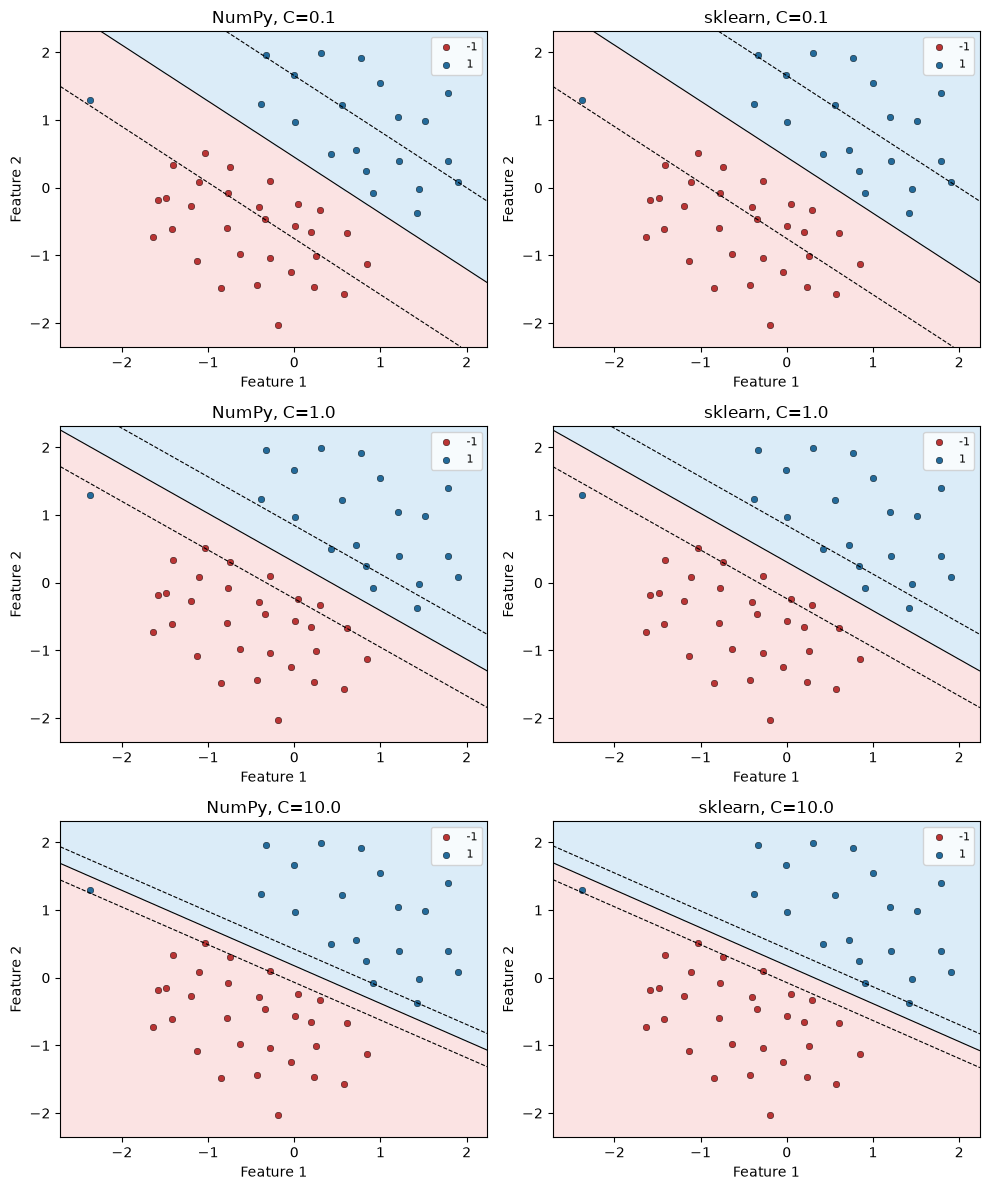

In [18]:
C_manual = [0.1, 1.0, 10.0]
########## Start of Your Code ##########
manual_models, reference_models, rows_t4 = {}, {}, []
for C in C_manual:
    manual = NumPyLinearSVM(C=C).fit(X_t4, y_t4)
    reference = SVC(kernel="linear", C=C, tol=1e-8).fit(X_t4, y_t4)
    manual_models[C], reference_models[C] = manual, reference
    objective_ref = manual.loss(X_t4, y_t4, reference.coef_[0], reference.intercept_[0])
    relative_gap = abs(manual.best_loss_ - objective_ref) / max(abs(objective_ref), 1e-12)
    assert manual.best_loss_ < manual.loss_history_[0]
    assert relative_gap <= 0.05, f"Objective gap too large for C={C}: {relative_gap}"
    assert accuracy_score(y_t4, manual.predict(X_t4)) >= 0.9
    for label, fitted, w, objective in [
        ("NumPy", manual, manual.w_, manual.best_loss_),
        ("sklearn", reference, reference.coef_[0], objective_ref)]:
        rows_t4.append({"C": C, "implementation": label,
            "train_accuracy": accuracy_score(y_t4, fitted.predict(X_t4)),
            "objective": objective, "margin_width": 2 / np.linalg.norm(w),
            "relative_objective_gap": relative_gap if label == "NumPy" else 0.0})
comparison_t4 = pd.DataFrame(rows_t4)
display(comparison_t4.round(6))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for C, ax in zip(C_manual, axes):
    losses = manual_models[C].loss_history_
    ax.plot(losses, linewidth=0.6, alpha=0.65, label="Raw objective")
    ax.plot(np.minimum.accumulate(losses), linewidth=1.1, label="Best so far")
    ax.set(xlabel="Update", ylabel="Objective", title=f"C={C}")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(3, 2, figsize=(10, 12))
for row, C in enumerate(C_manual):
    plot_decision_boundary(manual_models[C], X_t4, y_t4, axes[row, 0], f"NumPy, C={C}")
    plot_decision_boundary(reference_models[C], X_t4, y_t4, axes[row, 1], f"sklearn, C={C}")
fig.tight_layout()
plt.show()
########## End of Your Code ############
task_times["Task 4"] = time.perf_counter() - task_started


**Reference derivation.** With the specified active set,
$g_w=w-C\sum_{i\in A}y_ix_i$ and $g_b=-C\sum_{i\in A}y_i$.
The hinge part has a constant derivative within each active region and changes
at its boundary, so subgradient losses may oscillate. The best-iterate rule
retains a good approximate solution. The objective uses the same summed hinge
penalty and unregularized bias as the reference linear SVC; using a mean without
rescaling C would invalidate this comparison. Accuracy can agree even when
coefficients differ. No dual support-vector coefficients are computed by this
primal implementation.


## Task 5 Optional: Generalization and Overfitting
Reload T2 and make a **new stratified 80%/20% split**, with seed 42. Do not use
the model or best hyperparameters from Task 2: that search saw all of T2.
Use `StandardScaler -> SVC` with fixed C=1 and
gamma in `[0.01, 0.1, 1, 10, 100]`.

On the training subset only, run shuffled stratified five-fold CV with seed 42
and `return_train_score=True`. Plot the mean training and validation accuracies
with validation standard deviations. Fit each candidate on the full training
subset to count its support vectors. Select gamma by mean CV accuracy (ties use
the first candidate), freeze that choice, and evaluate **only that model once**
on the test subset. Draw boundaries for the smallest, selected and largest gamma.
Discuss underfitting and overfitting without assuming strictly monotonic results.

If you skip this task, leave `RUN_TASK5=False`; its cells then run without errors.


In [19]:
RUN_TASK5 = True


,gamma,mean_train_accuracy,mean_cv_accuracy,std_cv_accuracy,support_vectors
0,0.01,0.701562,0.70625,0.089704,130
1,0.10,0.942187,0.93750,0.044194,85
2,1.00,0.985938,0.97500,0.023385,42
3,10.00,1.000000,0.97500,0.023385,61
4,100.00,1.000000,0.93750,0.027951,135


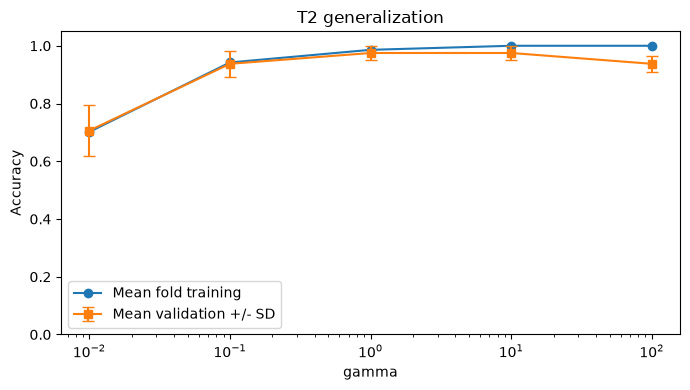

Selected gamma: 1
Selected tuning CV accuracy: 0.9750
Final independent test accuracy: 1.0000 (n=40)


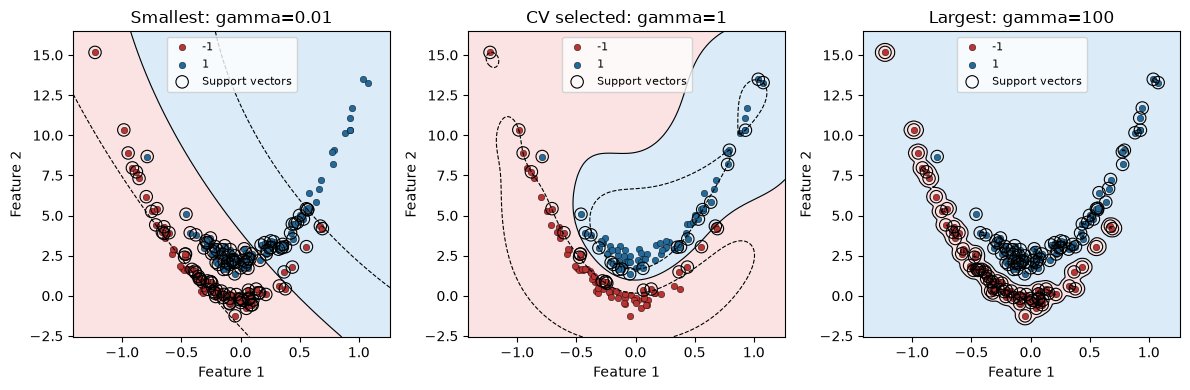

In [20]:
if RUN_TASK5:
    task_started = time.perf_counter()
    ########## Start of Your Code ##########
    t5_data = pd.read_csv(DATA_DIR / "T2_data.csv")
    X_t5 = t5_data.iloc[:, :2].to_numpy(dtype=float)
    y_t5 = t5_data["label"].to_numpy(dtype=int)
    X_t5_train, X_t5_test, y_t5_train, y_t5_test = train_test_split(
        X_t5, y_t5, test_size=0.2, random_state=SEED, stratify=y_t5)
    gamma_t5 = [0.01, 0.1, 1, 10, 100]
    pipeline_t5 = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf", C=1))])
    cv_t5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    search_t5 = GridSearchCV(pipeline_t5, {"svc__gamma": gamma_t5}, scoring="accuracy",
        cv=cv_t5, n_jobs=N_JOBS, return_train_score=True, error_score="raise")
    search_t5.fit(X_t5_train, y_t5_train)
    models_t5, rows_t5 = {}, []
    for i, gamma in enumerate(gamma_t5):
        model = Pipeline([("scaler", StandardScaler()),
                          ("svc", SVC(kernel="rbf", C=1, gamma=gamma))])
        model.fit(X_t5_train, y_t5_train)
        models_t5[gamma] = model
        rows_t5.append({"gamma": gamma,
            "mean_train_accuracy": search_t5.cv_results_["mean_train_score"][i],
            "mean_cv_accuracy": search_t5.cv_results_["mean_test_score"][i],
            "std_cv_accuracy": search_t5.cv_results_["std_test_score"][i],
            "support_vectors": int(model.named_steps["svc"].n_support_.sum())})
    results_t5 = pd.DataFrame(rows_t5)
    display(results_t5)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.semilogx(results_t5.gamma, results_t5.mean_train_accuracy, "o-", label="Mean fold training")
    ax.errorbar(results_t5.gamma, results_t5.mean_cv_accuracy,
                yerr=results_t5.std_cv_accuracy, fmt="s-", capsize=4, label="Mean validation +/- SD")
    ax.set(xscale="log", xlabel="gamma", ylabel="Accuracy", ylim=(0, 1.05), title="T2 generalization")
    ax.legend()
    fig.tight_layout()
    plt.show()
    selected_gamma_t5 = search_t5.best_params_["svc__gamma"]
    # Model selection is finished. This is the only test prediction in Task 5.
    y_t5_pred = search_t5.best_estimator_.predict(X_t5_test)
    test_accuracy_t5 = accuracy_score(y_t5_test, y_t5_pred)
    print("Selected gamma:", selected_gamma_t5)
    print(f"Selected tuning CV accuracy: {search_t5.best_score_:.4f}")
    print(f"Final independent test accuracy: {test_accuracy_t5:.4f} (n={len(y_t5_test)})")
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for gamma, role, ax in zip([gamma_t5[0], selected_gamma_t5, gamma_t5[-1]],
                              ["Smallest", "CV selected", "Largest"], axes):
        model = models_t5[gamma]
        support_raw = model.named_steps["scaler"].inverse_transform(
            model.named_steps["svc"].support_vectors_)
        plot_decision_boundary(model, X_t5_train, y_t5_train, ax,
                               f"{role}: gamma={gamma}", support_raw)
    fig.tight_layout()
    plt.show()
    ########## End of Your Code ############
    task_times["Task 5"] = time.perf_counter() - task_started


In [21]:
if RUN_TASK5:
    low, high = results_t5.iloc[0], results_t5.iloc[-1]
    display(Markdown(
        f"**Reference interpretation.** The smallest gamma has fold training/validation "
        f"accuracies **{low.mean_train_accuracy:.3f}/{low.mean_cv_accuracy:.3f}**; "
        f"the largest has **{high.mean_train_accuracy:.3f}/{high.mean_cv_accuracy:.3f}**. "
        f"The selected gamma is **{selected_gamma_t5:g}**. Compare the gap and boundary "
        "shape rather than interpreting gamma alone. Very local kernels may fit isolated "
        "training points well while losing validation accuracy. Support-vector counts "
        "depend on both the data and hyperparameters and need not be monotonic. The "
        "held-out set has only 40 samples: one different prediction changes its accuracy "
        "by 2.5 percentage points. Test results did not select the model."))


**Reference interpretation.** The smallest gamma has fold training/validation accuracies **0.702/0.706**; the largest has **1.000/0.938**. The selected gamma is **1**. Compare the gap and boundary shape rather than interpreting gamma alone. Very local kernels may fit isolated training points well while losing validation accuracy. Support-vector counts depend on both the data and hyperparameters and need not be monotonic. The held-out set has only 40 samples: one different prediction changes its accuracy by 2.5 percentage points. Test results did not select the model.

## Runtime record
These elapsed times include computation and figure generation after setup. Package installation, notebook kernel startup, and report writing are excluded.


In [22]:
print("Per-task CPU execution time (seconds):")
display(pd.Series(task_times, name="seconds").round(3).to_frame())
total_runtime = time.perf_counter() - notebook_started
print(f"Notebook elapsed time after imports: {total_runtime:.3f} seconds")


Per-task CPU execution time (seconds):


,seconds
Task 1,0.871
Task 2,5.888
Task 3,1.145
Task 4,0.865
Task 5,1.027


Notebook elapsed time after imports: 9.966 seconds
